In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}


from trips.utilities.weights import smoothed_holder_weights


# from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
# from pgkbsolver import MMGKB, IASGKB, MM2019GKB
# from f2019solver import MM2019FGK2019, IASFGK2019


from msolver import VanillaGKS

from msolver import MMGKS

from pgkbsolver import MMGKB

from fsolver import MMFGK

# Setup problem data

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

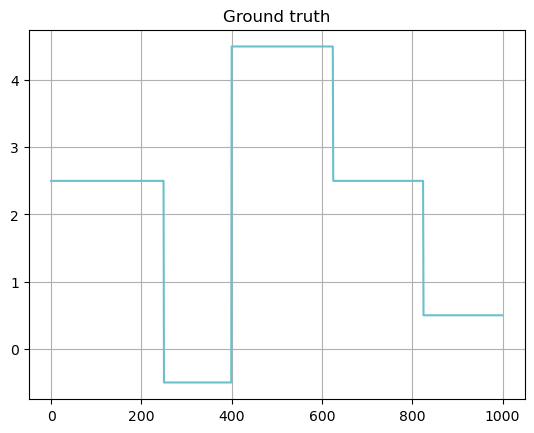

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


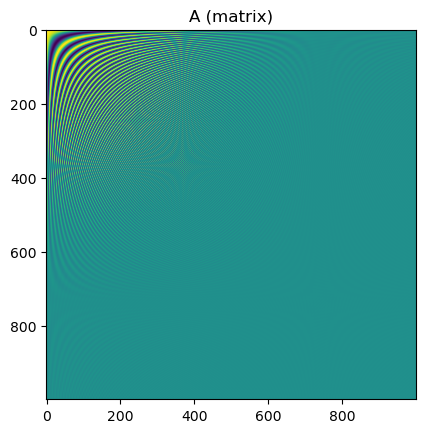

In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [6]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [7]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

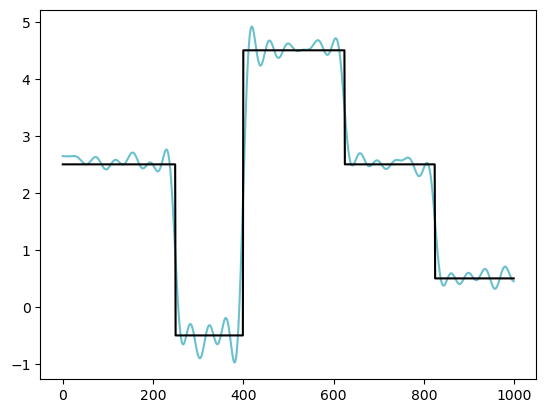

In [8]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [9]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-15

In [10]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)



epsilons = [ 1e2, 1e1, 1e0, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10 ]
all_data = []
for epsilon in epsilons:

    mm_weight_params = {
        "epsilon": epsilon,
        "q": 1.0,
    }

    mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


    # S-GKS
    mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
    
    # PS-GKS
    mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
    
    # PS-GKB
    mm_psgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    mm_psgkb_data = mm_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )
    
    # FGK
    mm_fgk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
    mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )


    all_data.append( (epsilon, mm_sgks_data, mm_psgks_data, mm_psgkb_data, mm_fgk_data)  ) 


734.4247114348133
773.4913540627327
792.7646435688165
786.7947212547227
678.4096966018841
398.1030990218177
261.6985788419615
222.5772537620482
207.12262435777706
199.1489349912947
194.4712497396449
191.68058160550132
189.98769984019867
188.9407545638505
188.3192580745528
187.93155030095286
187.67406298505784
187.50640959098223
187.3773626339308
187.25679805816196
187.13438220593392
187.03423039306728
186.96873930334675
186.92695705730347
186.90215045553626
186.88283133917605
186.8678029119946
186.86570858542063
186.87507125576715
186.89381598965608
186.91736376635816
186.9370501948805
186.95321071633865
186.96858885412058
186.98339953185004
186.99530261963395
187.005226466949
187.0143463042034
187.02335563902187
187.03179454279942
187.0382934908616
187.0430259484341
187.0470223036739
187.05021945655372
187.0521144980719
187.05344174096933
187.0546805216003
187.05544264799784
187.05577245421875
187.05598119143846
187.0561220229203
187.05598952199165
187.05550868385896
187.0549666846016

18705.294080734275
18705.293698480582
18705.29369998055
18705.293703025585
18705.293707325516
18705.293712357096
18705.29371740158
18705.293721817477
18705.29372529496
18705.293727695
18705.29372894258
18705.2937291251
18705.293728384007
18705.29372694434
18705.29372484101
18705.293722026938
18705.293718542005
18705.293714698448
18705.29371104673
18705.293708091915
18705.2937057665
18705.293704055963
18705.293703322848
18705.29370353186
18705.293704177544
18705.293704612748
18705.293704389005
18705.293703402913
18705.293701608996
18705.29369908239
18705.293695778026
18705.293691722967
18705.293687774618
18705.293684252218
18705.293681317013
18705.293679112492
18705.293677800455
18705.293677175636
18705.29367701463
18705.293677126494
18705.293677375797
18705.293677571663
18705.29367755691
18705.29367731022
18705.293676802095
18705.293675942696
18705.293674914363
18705.293673920576
18705.293672891086
18705.293671932173
18705.29367123494
18705.293670841605
18705.29367071378
18705.29367085

18705.29700490773


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:881: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


18705.29125986648
18705.294713549894
18705.288908321134
18705.29143305206
18705.29328139808
18705.29541364283
18705.293551976578
18705.293351005643
18705.293942215838
18705.293890937563
18705.293800440373
18705.29391881785
18705.29383500012
18705.29385506968
18705.293848617977
18705.293851746053
18705.293857280776
18705.293852495637
18705.293853992003
18705.293853924344
18705.29385401614
18705.293853725067
18705.29385396472
18705.293853914813
18705.29385384782
18705.29385387757
18705.29385387985
18705.293853878124
18705.29385387806
18705.293853878076
18705.29385387794
18705.29385387788
18705.293853877865
18705.293853877807
18705.29385387792
18705.293853877774
18705.29385387777
18705.293853877836
18705.29385387781
18705.29385387781
18705.293853877858
18705.293853877796
18705.29385387782
18705.293853877884
18705.293853877916
18705.29385387781
18705.293853877818
18705.29385387779
18705.293853877876
18705.29385387782
18705.293853877814
18705.29385387781
18705.293853877833
18705.29385387782

...

generating basis...: 100%|██████████| 124/124 [00:00<00:00, 1955.71it/s]


57.157919268227765


generating basis...: 100%|██████████| 125/125 [00:00<00:00, 1854.68it/s]


57.16650922216456


Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
5.202283198955106
Starting iteration 10
19.93163055681405
Starting iteration 11
18.24152826064132
Starting iteration 12
18.10833032866252
Starting iteration 13
17.02337018798272
Starting iteration 14
17.57855394118532
Starting iteration 15
18.189910211428703
Starting iteration 16
18.331113662968583
Starting iteration 17
19.081814902645903
Starting iteration 18
19.181087276991846
Starting iteration 19
19.864631935502462
Starting iteration 20
19.903450732635758
Starting iteration 21
20.089477332345453
Starting iteration 22
19.036229437099692
Starting iteration 23
17.783156840897785
Starting iteration 24
17.697686631379934
Starting iteration 25
18.863408332189977
Starting iteration 26
19.234853614606532
Starting iteration 27
20.0

In [11]:
sgks_rres = []
psgks_rres = []
psgkb_rres = []
psfgk_rres = []
for item in all_data:
    epsilon, sgks_data, psgks_data, psgkb_data, psfgk_data = item
    sgks_rres.append(sgks_data["rre_history"][-1])
    psgks_rres.append(psgks_data["rre_history"][-1])
    psgkb_rres.append(psgkb_data["rre_history"][-1])
    psfgk_rres.append(psfgk_data["rre_history"][-1])

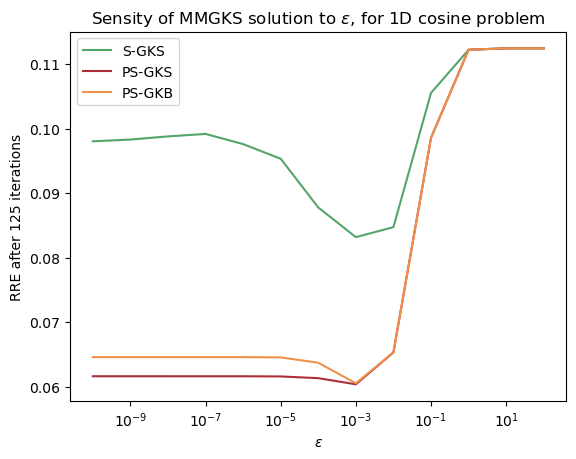

In [18]:
plt.semilogx(epsilons, sgks_rres, label="S-GKS", color=method_colors["S-GKS"])
plt.semilogx(epsilons, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"])
plt.semilogx(epsilons, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"])
# plt.semilogx(epsilons, psfgk_rres, label="FGK")
plt.xlabel("$\epsilon$")
plt.title("Sensity of MMGKS solution to $\epsilon$, for 1D cosine problem")
plt.ylabel("RRE after 125 iterations")
plt.legend()
plt.savefig("sensitivity.png", dpi=250)
plt.show()

In [19]:
method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

In [20]:
method_colors

{'GKS': 'C1',
 'S-GKS': 'C4',
 'resS-GKS': 'C4',
 'recS-GKS': 'C4',
 'PS-GKS': 'C2',
 'resPS-GKS': 'C2',
 'recPS-GKS': 'C2',
 'PS-GKB': 'C5',
 'FGK': 'C3',
 'FLSQR-I': 'C3',
 'FLSQR-R': 'C3',
 'FLSQR-W': 'C3',
 'IRW-FLSQR': 'C3'}